This is to explore Long Short-Term Memory (LSTM) networks, a type of recurrent neural network (RNN), be use for stock price prediction

In [174]:
#
import pandas as pd
import numpy as np
import math
import matplotlib.pyplot as plt

#import os
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.tsa.stattools import adfuller

import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout
from sklearn.metrics import mean_squared_error

import yfinance as yf

In [175]:
import warnings
warnings.filterwarnings("ignore")

In [176]:
# Data source from yfinance as below
#   tentatively retreive 3 years stock data

company = "0386.HK"
df_HKstock = yf.download(company, start="2023-01-01", end="2026-01-01",
                    auto_adjust=True ).droplevel('Ticker', axis=1)
df_HKstock

[*********************100%***********************]  1 of 1 completed


Price,Close,High,Low,Open,Volume
Date,,,,,
2023-01-03,2.919594,2.934880,2.858451,2.858451,58084791
2023-01-04,2.927237,2.927237,2.889022,2.919594,72997430
2023-01-05,2.911951,2.942522,2.904308,2.934880,70281193
2023-01-06,2.904308,2.927237,2.896665,2.927237,50935388
2023-01-09,2.934880,2.942522,2.911951,2.927237,56317277
...,...,...,...,...,...
2025-12-23,4.274738,4.303047,4.236991,4.255865,64714422
2025-12-24,4.274738,4.274738,4.274738,4.274738,0
2025-12-29,4.331357,4.378539,4.274738,4.284174,171003780


In [177]:
# Save copy to CSV
df_HKstock.to_csv('0386.HK.csv')

In [178]:
#
df_source = pd.read_csv("0386.HK.csv")
df_source

,Date,Close,High,Low,Open,Volume
0,2023-01-03,2.919594,2.934880,2.858451,2.858451,58084791
1,2023-01-04,2.927237,2.927237,2.889022,2.919594,72997430
2,2023-01-05,2.911951,2.942522,2.904308,2.934880,70281193
3,2023-01-06,2.904308,2.927237,2.896665,2.927237,50935388
4,2023-01-09,2.934880,2.942522,2.911951,2.927237,56317277
...,...,...,...,...,...,...
730,2025-12-23,4.274738,4.303047,4.236991,4.255865,64714422
731,2025-12-24,4.274738,4.274738,4.274738,4.274738,0
732,2025-12-29,4.331357,4.378539,4.274738,4.284174,171003780
733,2025-12-30,4.416285,4.482341,4.312484,4.321920,283639620


In [179]:
# Set Date
df_source["Date"] = pd.to_datetime(df_source["Date"], format="%Y-%m-%d")
df_source

,Date,Close,High,Low,Open,Volume
0,2023-01-03,2.919594,2.934880,2.858451,2.858451,58084791
1,2023-01-04,2.927237,2.927237,2.889022,2.919594,72997430
2,2023-01-05,2.911951,2.942522,2.904308,2.934880,70281193
3,2023-01-06,2.904308,2.927237,2.896665,2.927237,50935388
4,2023-01-09,2.934880,2.942522,2.911951,2.927237,56317277
...,...,...,...,...,...,...
730,2025-12-23,4.274738,4.303047,4.236991,4.255865,64714422
731,2025-12-24,4.274738,4.274738,4.274738,4.274738,0
732,2025-12-29,4.331357,4.378539,4.274738,4.284174,171003780
733,2025-12-30,4.416285,4.482341,4.312484,4.321920,283639620


In [180]:
df_source.info()

<class 'pandas.DataFrame'>
RangeIndex: 735 entries, 0 to 734
Data columns (total 6 columns):
 #   Column  Non-Null Count  Dtype         
---  ------  --------------  -----         
 0   Date    735 non-null    datetime64[us]
 1   Close   735 non-null    float64       
 2   High    735 non-null    float64       
 3   Low     735 non-null    float64       
 4   Open    735 non-null    float64       
 5   Volume  735 non-null    int64         
dtypes: datetime64[us](1), float64(4), int64(1)
memory usage: 34.6 KB


In [181]:
# Set Date as index - time series data
df_source = df_source.set_index('Date', ) 
df_source.info()

<class 'pandas.DataFrame'>
DatetimeIndex: 735 entries, 2023-01-03 to 2025-12-31
Data columns (total 5 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   Close   735 non-null    float64
 1   High    735 non-null    float64
 2   Low     735 non-null    float64
 3   Open    735 non-null    float64
 4   Volume  735 non-null    int64  
dtypes: float64(4), int64(1)
memory usage: 34.5 KB


In [182]:
df = df_source
df

,Close,High,Low,Open,Volume
Date,,,,,
2023-01-03,2.919594,2.934880,2.858451,2.858451,58084791
2023-01-04,2.927237,2.927237,2.889022,2.919594,72997430
2023-01-05,2.911951,2.942522,2.904308,2.934880,70281193
2023-01-06,2.904308,2.927237,2.896665,2.927237,50935388
2023-01-09,2.934880,2.942522,2.911951,2.927237,56317277
...,...,...,...,...,...
2025-12-23,4.274738,4.303047,4.236991,4.255865,64714422
2025-12-24,4.274738,4.274738,4.274738,4.274738,0
2025-12-29,4.331357,4.378539,4.274738,4.284174,171003780


In [183]:
# Data pre-processing
df.isnull().sum()

Close     0
High      0
Low       0
Open      0
Volume    0
dtype: int64

In [184]:
# This is preserve as for handling missing values, if applicable
df.bfill()

,Close,High,Low,Open,Volume
Date,,,,,
2023-01-03,2.919594,2.934880,2.858451,2.858451,58084791
2023-01-04,2.927237,2.927237,2.889022,2.919594,72997430
2023-01-05,2.911951,2.942522,2.904308,2.934880,70281193
2023-01-06,2.904308,2.927237,2.896665,2.927237,50935388
2023-01-09,2.934880,2.942522,2.911951,2.927237,56317277
...,...,...,...,...,...
2025-12-23,4.274738,4.303047,4.236991,4.255865,64714422
2025-12-24,4.274738,4.274738,4.274738,4.274738,0
2025-12-29,4.331357,4.378539,4.274738,4.284174,171003780


In [185]:
# Calculate moving averages and daily returns

df['20-day MA'] = df['Close'].rolling(window=20).mean()
df['50-day MA'] = df['Close'].rolling(window=50).mean()
df['Daily Return'] = df['Close'].pct_change()

In [186]:
# To check NaN
df[df.isna().values==True].drop_duplicates()

,Close,High,Low,Open,Volume,20-day MA,50-day MA,Daily Return
Date,,,,,,,,
2023-01-03,2.919594,2.934880,2.858451,2.858451,58084791,NaN,NaN,NaN
2023-01-04,2.927237,2.927237,2.889022,2.919594,72997430,NaN,NaN,0.002618
2023-01-05,2.911951,2.942522,2.904308,2.934880,70281193,NaN,NaN,-0.005222
2023-01-06,2.904308,2.927237,2.896665,2.927237,50935388,NaN,NaN,-0.002625
2023-01-09,2.934880,2.942522,2.911951,2.927237,56317277,NaN,NaN,0.010526
2023-01-10,2.934880,2.950165,2.919594,2.934880,66480816,NaN,NaN,0.000000
2023-01-11,2.965451,2.996023,2.934880,2.934880,136384472,NaN,NaN,0.010417
2023-01-12,3.018952,3.026595,2.957808,2.957808,123655194,NaN,NaN,0.018041
2023-01-13,3.049524,3.049524,3.003666,3.041881,82369860,NaN,NaN,0.010127


In [187]:
df = df.dropna()   # Drop all NaN
df

,Close,High,Low,Open,Volume,20-day MA,50-day MA,Daily Return
Date,,,,,,,,
2023-03-16,3.531027,3.599813,3.508099,3.546313,174803627,3.343394,3.209413,-0.023256
2023-03-17,3.745029,3.760315,3.553956,3.561599,368017156,3.371673,3.225922,0.060606
2023-03-20,3.576885,3.798529,3.561599,3.699172,286854795,3.390398,3.238915,-0.044898
2023-03-21,3.584528,3.638028,3.515741,3.592170,129379902,3.407976,3.252367,0.002137
2023-03-22,3.645671,3.691529,3.607457,3.607457,136763006,3.429759,3.267194,0.017058
...,...,...,...,...,...,...,...,...
2025-12-23,4.274738,4.303047,4.236991,4.255865,64714422,4.205379,4.102238,0.004435
2025-12-24,4.274738,4.274738,4.274738,4.274738,0,4.210569,4.111486,0.000000
2025-12-29,4.331357,4.378539,4.274738,4.284174,171003780,4.216231,4.121489,0.013245


In [ ]:
Optimal Hyperparameter Configuration: {'batch_size': 32, 'epochs': 20, 'model__optimizer': 'adam', 'model__units': 16}

In [188]:
# Configuration

# For ~ 80:20 Split
test_days = 135

# choose the number of days on which to base our predictions 
nb_days = 60

# Number of days into the future we want to predict
n_steps_out = 10

#
epochsMS=20 
batch_sizeMS = 32
epochs2=30 
batch_size2 = 32

#new
unitsMS = 16

In [189]:
# For normailized Data

# from sklearn.preprocessing import MinMaxScaler

scaler = MinMaxScaler(feature_range=(0,1))  
scaled_data = scaler.fit_transform(df['Close'].values.reshape(-1,1))

In [190]:
# ADF Test : p-value < 0.05 for stationary data

#from statsmodels.tsa.stattools import adfuller

close_series = df['Close']
def check_stationarity(series):
    result = adfuller(series.dropna())  # Drop NaN values if any
    print("ADF Statistic:", result[0])
    print("p-value:", result[1])
    if result[1] < 0.05:
        print("The series is stationary.")
    else:
        print("The series is not stationary.")

check_stationarity(close_series)

ADF Statistic: -2.4117828361823066
p-value: 0.13843837002208248
The series is not stationary.


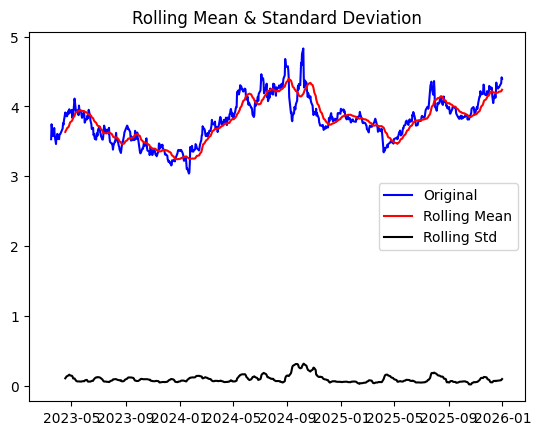

Results of Dickey-Fuller Test:
Test Statistic                  -2.411783
p-value                          0.138438
#Lags Used                       0.000000
Number of Observations Used    685.000000
Critical Value (1%)             -3.439932
Critical Value (5%)             -2.865769
Critical Value (10%)            -2.569022
dtype: float64


In [191]:
#... The following cells are use for model(s), such as LSTM in transformation
#... test stationarity with DFT

close_series = df['Close']
def test_stationarity(timeseries):
    '''
    Input: timeseries (dataframe): timeseries for which we want to study the stationarity
    '''
    
    #Determing rolling statistics
    rolmean = timeseries.rolling(20).mean()
    rolstd = timeseries.rolling(20).std()

    #Plot rolling statistics:
    orig = plt.plot(timeseries, color='blue',label='Original')
    mean = plt.plot(rolmean, color='red', label='Rolling Mean')
    std = plt.plot(rolstd, color='black', label = 'Rolling Std')
    plt.legend(loc='best')
    plt.title('Rolling Mean & Standard Deviation')
    plt.show(block=False)

    #Perform Dickey-Fuller test:
    print('Results of Dickey-Fuller Test:')
    dftest = adfuller(timeseries, autolag='AIC')
    dfoutput = pd.Series(dftest[0:4], index=['Test Statistic','p-value',\
                                             '#Lags Used','Number of Observations Used'])
    for key,value in dftest[4].items():
        dfoutput['Critical Value (%s)'%key] = value
    print(dfoutput)

test_stationarity(close_series)

<Figure size 640x480 with 0 Axes>

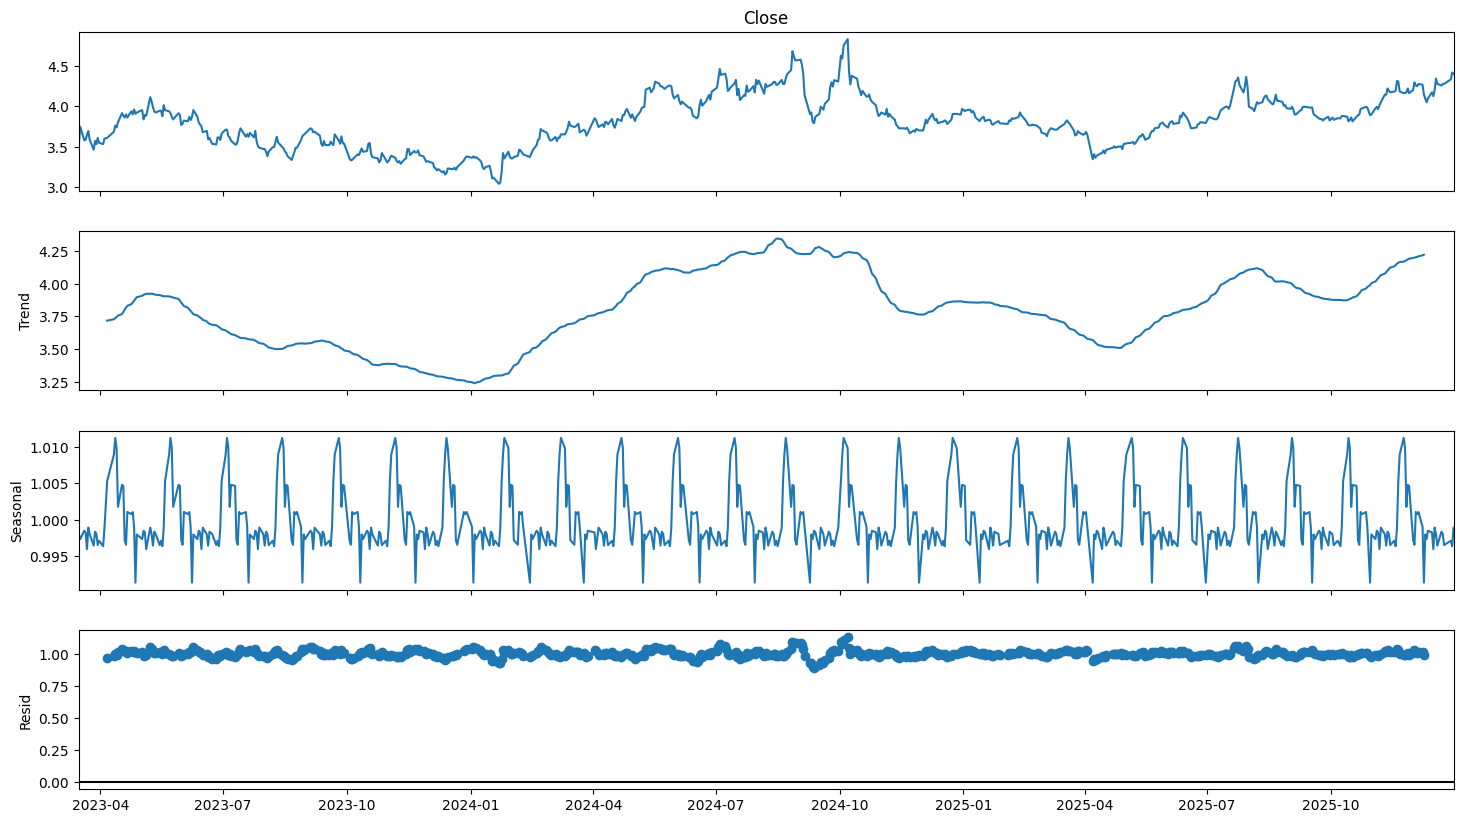

In [192]:
#from statsmodels.tsa.seasonal import seasonal_decompose

#To plot & view the trend and the seasonality
# here set the period to 28 as monthly average 

df_close = df['Close']
result = seasonal_decompose(df_close, model='multiplicative',period=28)
fig = plt.figure()  
fig = result.plot()  
fig.set_size_inches(16, 9)

Text(0.5, 1.0, 'Transformed data')

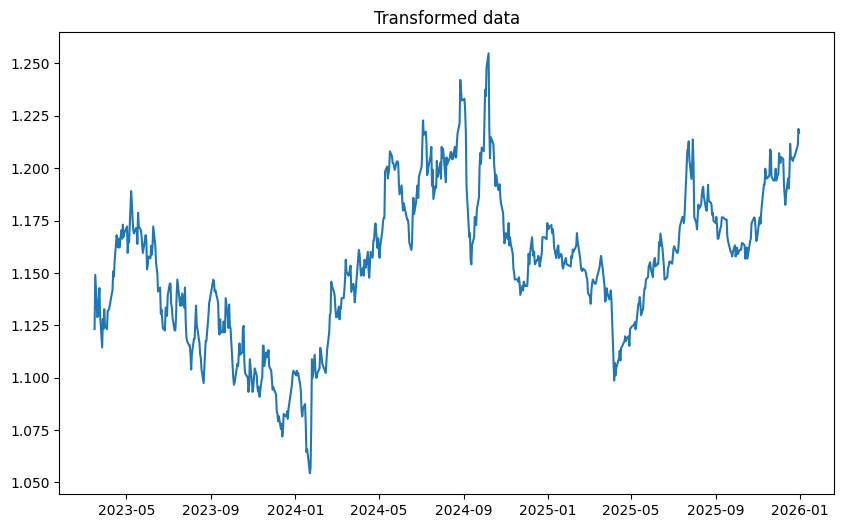

In [193]:
#... To apply log transform to reduce the trends effect while square root transform to flatten 

df_close_log = df_close.apply(np.log)
df_close_tf = df_close_log.apply(np.sqrt)

plt.figure(figsize = (10,6))
plt.plot(df_close_tf)
plt.title('Transformed data')

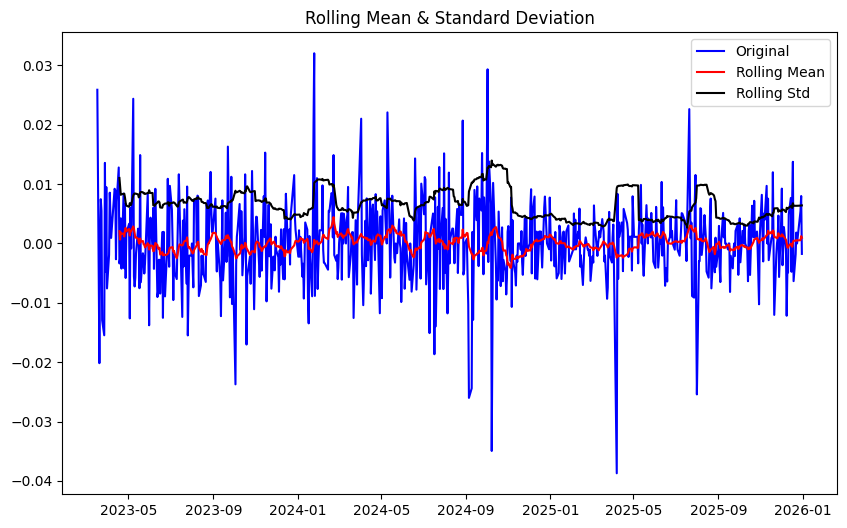

Results of Dickey-Fuller Test:
Test Statistic                -1.042778e+01
p-value                        1.640538e-18
#Lags Used                     9.000000e+00
Number of Observations Used    6.750000e+02
Critical Value (1%)           -3.440075e+00
Critical Value (5%)           -2.865831e+00
Critical Value (10%)          -2.569055e+00
dtype: float64


In [158]:
#... classical methold differenciating to handel with trand and seasonality
df_close_shift = df_close_tf - df_close_tf.shift()

df_close_shift.dropna(inplace=True)
plt.figure(figsize = (10,6))
test_stationarity(df_close_shift)

check p-value

In [194]:
#...MS LSTM
def preprocess_lstm(sequence, n_steps,n_features):
    X, y = list(), list()
    for i in range(len(sequence)):
        # find the end of this pattern
        end_ix = i + n_steps
        # check if we are beyond the sequence
        if end_ix >= len(sequence):
            break
        # gather input and output parts of the pattern
        seq_x, seq_y = sequence[i:end_ix], sequence[end_ix]
        X.append(seq_x)
        y.append(seq_y)
        
    X = np.array(X)
    y = np.array(y)

    X = X.reshape((X.shape[0], X.shape[1], n_features))
    return X, y

# choose the number of days on which to base our predictions 
#nb_days = 60
n_features = 1

X, y = preprocess_lstm(df_close_shift.to_numpy(), nb_days, n_features)

#Split the data set between the training set and the test set (20%)
#test_days = 135 

X_train, y_train = X[:-test_days], y[:-test_days]
X_test, y_test = X[-test_days:], y[-test_days:]

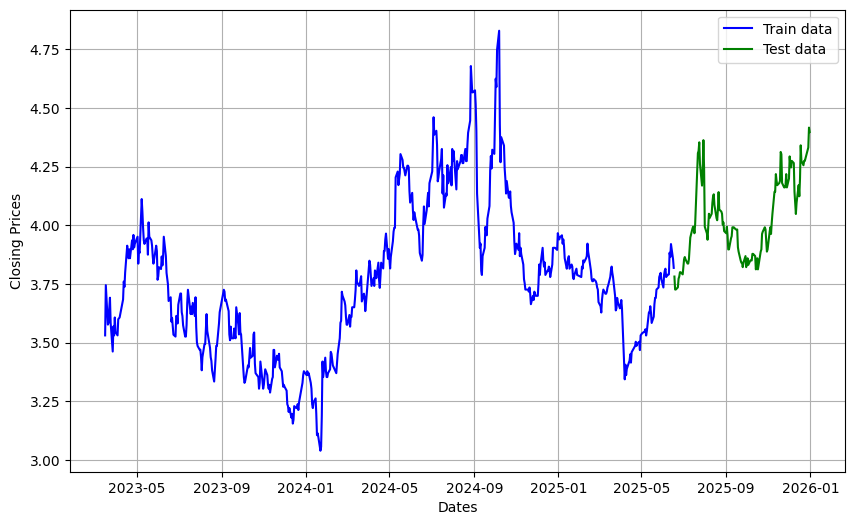

In [195]:
#... Split Data
train_original = df_close.iloc[:-test_days]
test_original = df_close.iloc[-test_days:]

plt.figure(figsize=(10,6))
plt.grid(True)
plt.xlabel('Dates')
plt.ylabel('Closing Prices')
plt.plot(train_original, 'b', label='Train data')
plt.plot(test_original, 'g', label='Test data')
plt.legend()

In [196]:
#... LSTM Vanilla LSTM
def vanilla_LSTM():
    model = Sequential()    
    model.add(LSTM(units=unitsMS, input_shape=(nb_days, n_features)))
    model.add(Dense(1))
    return model

#
model = vanilla_LSTM()
model.summary()
model.compile(optimizer='adam', 
              loss='mean_squared_error',
              metrics=[tf.keras.metrics.MeanAbsoluteError()])    

Model: "sequential_11"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ lstm_11 (LSTM)                       │ (None, 16)                  │           1,152 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_11 (Dense)                     │ (None, 1)                   │              17 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 1,169 (4.57 KB)

 Trainable params: 1,169 (4.57 KB)

 Non-trainable params: 0 (0.00 B)

In [197]:
#...Train and evaluate model
model.fit(X_train, 
          y_train, 
          epochs=epochsMS, 
          batch_size = batch_sizeMS)

Epoch 1/20
16/16 ━━━━━━━━━━━━━━━━━━━━ 2s 11ms/step - loss: 5.6920e-05 - mean_absolute_error: 0.0055
Epoch 2/20
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 5.1584e-05 - mean_absolute_error: 0.0052
Epoch 3/20
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 5.1300e-05 - mean_absolute_error: 0.0052
Epoch 4/20
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 5.2641e-05 - mean_absolute_error: 0.0053
Epoch 5/20
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 5.0570e-05 - mean_absolute_error: 0.0052
Epoch 6/20
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 5.0767e-05 - mean_absolute_error: 0.0052
Epoch 7/20
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 5.1278e-05 - mean_absolute_error: 0.0052
Epoch 8/20
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 5.2940e-05 - mean_absolute_error: 0.0053
Epoch 9/20
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 5.1094e-05 - mean_absolute_error: 0.0052
Epoch 10/20
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 5.0795e-05 - mean_absolute_error: 0.0052

In [198]:
#...
# Evaluate the model on the test data using
print("Evaluate on test data")
results = model.evaluate(X_test, y_test, batch_size=32)
print("Test MSE:", results[0])
print("Test MAE:", results[1])

Evaluate on test data
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 3.2133e-05 - mean_absolute_error: 0.0040  
Test MSE: 3.2133124477695674e-05
Test MAE: 0.004038142506033182


5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 36ms/step


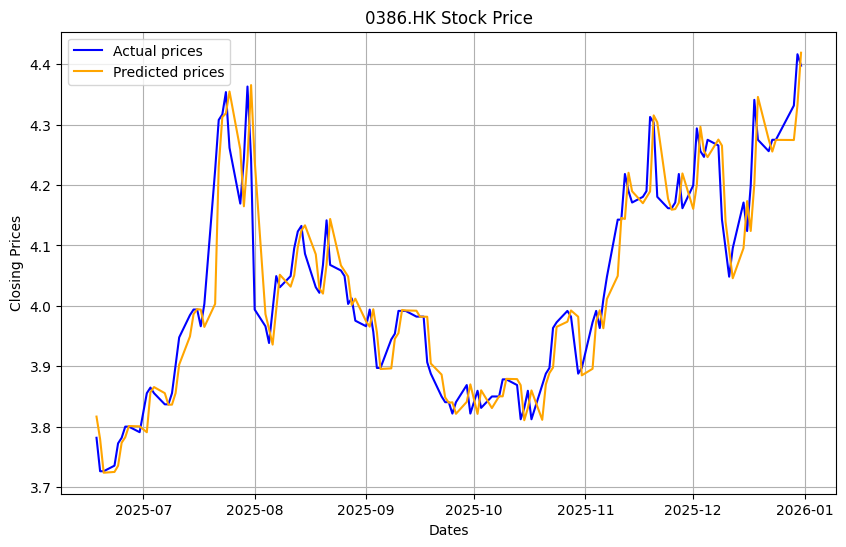

In [199]:
#...
# Prediction
y_pred = model.predict(X_test)

# We create a dataframe from y_pred to have date-time indexes.
pred_data = pd.DataFrame(y_pred[:,0], test_original.index,columns=['Close'])

# Apply inverse transformation from 1.d

# Add the differenciation term
pred_data['Close'] = pred_data['Close'] + df_close_tf.shift().values[-test_days:] 

# Take the square, and the exponent
pred_data = pred_data.apply(np.square)
pred_data = pred_data.apply(np.exp)

# Plot actual prices vs predicted prices 
plt.figure(figsize=(10,6))
plt.grid(True)
plt.xlabel('Dates')
plt.ylabel('Closing Prices')
plt.plot(test_original,'b',label='Actual prices')
plt.plot(pred_data, 'orange',label='Predicted prices')
#plt.title(' Stock Price')
plt.title(company + ' Stock Price')

plt.legend()

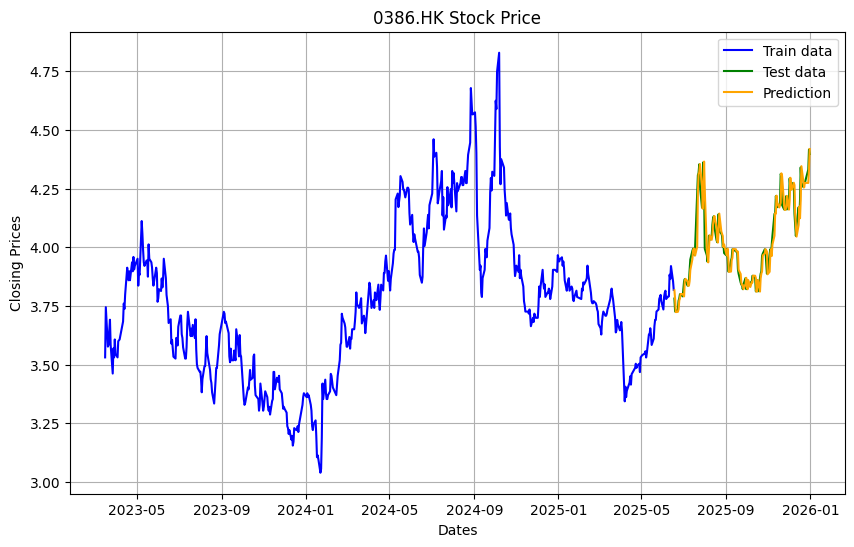

In [200]:
#...
plt.figure(figsize=(10,6))
plt.grid(True)
plt.xlabel('Dates')
plt.ylabel('Closing Prices')
plt.plot(train_original, 'b', label='Train data')
plt.plot(test_original, 'g', label='Test data')
plt.plot(pred_data, 'orange', label='Prediction')
plt.title(company + ' Stock Price')
plt.legend()

In [201]:
#...Multiple-Step LSTM
def preprocess_multistep_lstm(sequence, n_steps_in, n_steps_out, features):
    X, y = list(), list()
    for i in range(len(sequence)) :
        # find the end of this pattern
        end_ix = i + n_steps_in
        out_end_ix = end_ix + n_steps_out
        # check if we are beyond the sequence
        if out_end_ix > len(sequence):
            break
        # gather input and output parts of the pattern
        seq_x, seq_y = sequence[i:end_ix], sequence[end_ix:out_end_ix]
        X.append(seq_x)
        y.append(seq_y)

    X = np.array(X)
    y = np.array(y)

    X = X.reshape((X.shape[0], X.shape[1], n_features))
    
    return X, y

# Number of days into the future we want to predict
#n_steps_out = 10

# choose the number of days on which to base our predictions 
#nb_days = 60

n_features = 1

X, y = preprocess_multistep_lstm(df_close_shift.to_numpy(), nb_days, n_steps_out, n_features)

# Split the data set between the training set and the test set (20%)
#test_days = 135 

X_train, y_train = X[:-test_days], y[:-test_days]
X_test, y_test = X[-test_days:], y[-test_days:]


In [202]:
# Optimal lSTM model
#import tensorflow as tf
#from tensorflow.keras.models import Sequential
#from tensorflow.keras.layers import LSTM, Dense
#import numpy as np
#import pandas as pd
#import matplotlib.pyplot as plt

# 1. Define the final optimized model architecture
def create_optimal_multistep_LSTM():
    model = Sequential()    
    # Using the optimal units discovered by GridSearchCV (32 neurons)
    model.add(LSTM(units=unitsMS, input_shape=(nb_days, n_features)))
    model.add(Dense(n_steps_out))
    
    # Compiling with the optimal optimizer ('adam')
    model.compile(optimizer='adam', 
                  loss='mean_squared_error',
                  metrics=[tf.keras.metrics.MeanAbsoluteError()])
    return model

# 2. Instantiate and display final model structure
optimal_model = create_optimal_multistep_LSTM()
optimal_model.summary()

# 3. Train the model using the optimal batch_size (32) and epochs (30)
print("Training the final optimal model...")
history = optimal_model.fit(X_train, 
                            y_train, 
                            epochs=epochsMS, 
                            batch_size=batch_sizeMS,
                            verbose=1)

# 4. Evaluate the optimal model directly on the test set
print("\nEvaluating on test data...")
test_results = optimal_model.evaluate(X_test, y_test, batch_size=32)
print(f"Optimal Model Test MSE: {test_results[0]:.6f}")
print(f"Optimal Model Test MAE: {test_results[1]:.6f}")


Model: "sequential_12"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ lstm_12 (LSTM)                       │ (None, 16)                  │           1,152 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_12 (Dense)                     │ (None, 10)                  │             170 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 1,322 (5.16 KB)

 Trainable params: 1,322 (5.16 KB)

 Non-trainable params: 0 (0.00 B)

Training the final optimal model...
Epoch 1/20
16/16 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - loss: 5.2914e-05 - mean_absolute_error: 0.0053
Epoch 2/20
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 5.2936e-05 - mean_absolute_error: 0.0053
Epoch 3/20
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 5.2393e-05 - mean_absolute_error: 0.0053
Epoch 4/20
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 5.1855e-05 - mean_absolute_error: 0.0052
Epoch 5/20
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 5.1684e-05 - mean_absolute_error: 0.0052
Epoch 6/20
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 5.1694e-05 - mean_absolute_error: 0.0052
Epoch 7/20
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 5.1737e-05 - mean_absolute_error: 0.0052
Epoch 8/20
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 5.1964e-05 - mean_absolute_error: 0.0053
Epoch 9/20
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 5.2209e-05 - mean_absolute_error: 0.0053
Epoch 10/20
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 5.31

In [203]:
import pickle
with open ('optimal_model.pk1', 'wb') as f:
    pickle.dump(model, f)

In [204]:
with open('optimal_model.pk1', 'rb') as f:
    loaded_model = pickle.load(f)

For model tuning gridsearchCV,

In [168]:
# !pip install scikeras

from scikeras.wrappers import KerasRegressor
from sklearn.model_selection import GridSearchCV

# Define the model-building function to accept tunable hyperparameters (units, optimizer)
def create_vanilla_multistep_LSTM(units=unitsMS, optimizer='adam'):
    model = Sequential()    
    model.add(LSTM(units=units, input_shape=(nb_days, n_features)))
    model.add(Dense(n_steps_out))
    model.compile(optimizer=optimizer, 
                  loss='mean_squared_error',
                  metrics=[tf.keras.metrics.MeanAbsoluteError()])
    return model


In [169]:
# 1. Wrap the Keras model into a Scikit-learn compatible Regressor
# Basic default parameters are set here and will be optimized by the param_grid
keras_regressor = KerasRegressor(
    model=create_vanilla_multistep_LSTM, 
    epochs=epochsMS, 
    batch_size=batch_sizeMS, 
    verbose=0
)

# 2. Define the hyperparameter search grid
# Note: SciKeras requires internal model parameters to be prefixed with "model__"
param_grid = {
    'model__units': [16, 32, 64],
    'model__optimizer': ['adam', 'rmsprop'],
    'batch_size': [16, 32, 64],
    'epochs': [20, 30, 50]
}

# 3. Initialize GridSearchCV
# Using 3-Fold Cross-Validation for hyperparameter grid optimization
grid = GridSearchCV(
    estimator=keras_regressor, 
    param_grid=param_grid, 
    cv=3, 
    scoring='neg_mean_squared_error',
    n_jobs=-1   # Uses all available CPU cores for parallel processing
)

print("Executing GridSearchCV optimization process...")
grid_result = grid.fit(X_train, y_train)

# 4. Display optimization results
print(f"Best Cross-Validation Score (MSE): {-grid_result.best_score_:.6f}")
print(f"Optimal Hyperparameter Configuration: {grid_result.best_params_}")


Executing GridSearchCV optimization process...
Best Cross-Validation Score (MSE): 0.000051
Optimal Hyperparameter Configuration: {'batch_size': 32, 'epochs': 20, 'model__optimizer': 'adam', 'model__units': 16}


In [170]:
# Extract the best estimator discovered by grid search
best_model = grid_result.best_estimator_

print("Evaluating optimal model on Out-of-Sample Test Set...")
# SciKeras score returns Negative MSE (to align with GridSearchCV's maximization principle)
test_neg_mse = best_model.score(X_test, y_test)
print(f"Test Set MSE Evaluation: {-test_neg_mse:.6f}")

# Generate multi-step test predictions
y_pred = best_model.predict(X_test)


Evaluating optimal model on Out-of-Sample Test Set...
Test Set MSE Evaluation: 0.040639


In [171]:
import pickle
with open ('best_model.pk1', 'wb') as f:
    pickle.dump(model, f)

In [172]:
with open('best_model.pk1', 'rb') as f:
    loaded_model = pickle.load(f)


For normal execution,

In [205]:
# Generate multi-step out-of-sample predictions
y_pred = optimal_model.predict(X_test)

5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 36ms/step


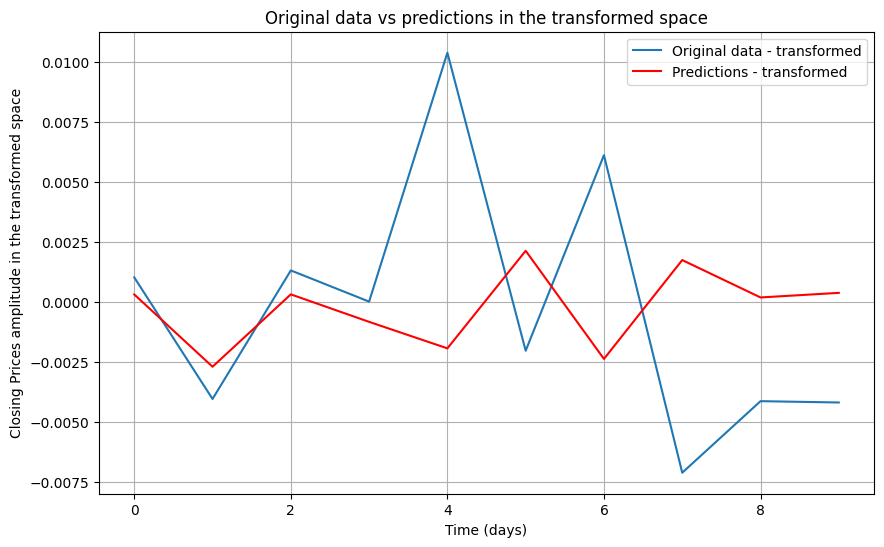

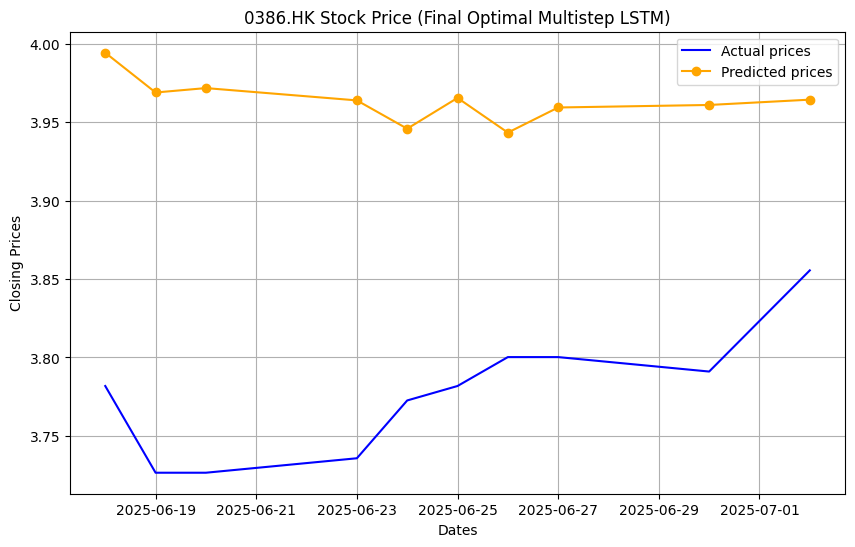

In [206]:

# Extract predictions for the first day of the testing horizon (the_day = 0)
the_day = 0
y_pred_days = y_pred[the_day,:]

# Plot original data vs predictions in the transformed space
plt.figure(figsize=(10,6))
plt.grid(True)
plt.plot(y_test[the_day,:], label='Original data - transformed')
plt.plot(y_pred_days, color='red', label='Predictions - transformed')
plt.xlabel('Time (days)')
plt.ylabel('Closing Prices amplitude in the transformed space')
plt.title('Original data vs predictions in the transformed space')
plt.legend()
plt.show()

# Execute Inverse Transformation to revert back to actual stock prices
pred_diff_cumsum = y_pred_days.cumsum()

base_number = df_close_tf.values[-test_days+the_day+nb_days-1]
idx = test_original.iloc[the_day:the_day+n_steps_out].index

pred_tf = pd.Series(base_number, index=idx)
pred_tf = pred_tf.add(pred_diff_cumsum, fill_value=0)

# Square the values, then apply the Exponential function to invert Log-Sqrt transforms
pred_log = pred_tf.apply(np.square)
pred = pred_log.apply(np.exp)

# Plot actual vs predicted final stock prices
plt.figure(figsize=(10,6))
plt.grid(True)
plt.xlabel('Dates')
plt.ylabel('Closing Prices')
plt.plot(test_original.iloc[max(0, the_day-30):the_day+n_steps_out], 'b', label='Actual prices')
plt.plot(pred, '-o', color='orange', label='Predicted prices')
plt.title(company + ' Stock Price (Final Optimal Multistep LSTM)')
plt.legend()
plt.show()


In [207]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# 1. Extract aligned true prices and predicted values
y_true_final = test_original.iloc[the_day : the_day + n_steps_out].values
y_pred_final = pred.values

# 2. Compute final evaluation metrics
mae = mean_absolute_error(y_true_final, y_pred_final)
mse = mean_squared_error(y_true_final, y_pred_final)
rmse = np.sqrt(mse)
mape = np.mean(np.abs((y_true_final - y_pred_final) / y_true_final)) * 100
r2 = r2_score(y_true_final, y_pred_final)

# 3. Calculate Directional Accuracy (Trend matching performance)
actual_direction = np.diff(y_true_final) > 0
predicted_direction = np.diff(y_pred_final) > 0
directional_accuracy = np.mean(actual_direction == predicted_direction) * 100

# 4. Display final evaluation summary
print("======= Final Optimal Multistep LSTM Evaluation Summary =======")
print(f"Mean Absolute Error (MAE)            : {mae:.4f}")
print(f"Root Mean Squared Error (RMSE)       : {rmse:.4f}")
print(f"Mean Absolute Percentage Error (MAPE): {mape:.2f}%")
print(f"Directional Accuracy (DA)            : {directional_accuracy:.2f}%")
print(f"Coefficient of Determination (R²)    : {r2:.4f}")


======= Final Optimal Multistep LSTM Evaluation Summary =======
Mean Absolute Error (MAE)            : 0.1868
Root Mean Squared Error (RMSE)       : 0.1916
Mean Absolute Percentage Error (MAPE): 4.96%
Directional Accuracy (DA)            : 33.33%
Coefficient of Determination (R²)    : -24.6084


In [219]:
# Follow from ADF Test if series is stationary
scaler = MinMaxScaler()
df['Close'] = scaler.fit_transform(df[['Close']])

In [220]:
# Train and Verify Split (80:20 Ratio)
#from sklearn.model_selection import train_test_split

def create_dataset(dataset, look_back=1):
    dataX, dataY = [], []
    for i in range(len(dataset) - look_back):
        dataX.append(dataset[i:(i + look_back)])
        dataY.append(dataset[i + look_back])
    return np.array(dataX), np.array(dataY)

close_values = df['Close'].values 

X, Y = create_dataset(close_values, look_back=30)

trainX, testX, trainY, testY = train_test_split(X, Y, test_size=0.2, shuffle=False)


In [221]:
# Data for LSTM 
trainX = np.reshape(trainX, (trainX.shape[0], trainX.shape[1], 1))
testX = np.reshape(testX, (testX.shape[0], testX.shape[1], 1))

In [215]:
#1 LSTM ***SKIP
model = Sequential()
model.add(LSTM(units=50, input_shape=(30, 1)))
model.add(Dense(units=1))
model.compile(loss='mean_squared_error', optimizer='adam')
model.summary()
model.fit(trainX, trainY, epochs=epochs2, batch_size=batch_size2)

Model: "sequential_15"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ lstm_18 (LSTM)                       │ (None, 50)                  │          10,400 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_18 (Dense)                     │ (None, 1)                   │              51 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 10,451 (40.82 KB)

 Trainable params: 10,451 (40.82 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/30
17/17 ━━━━━━━━━━━━━━━━━━━━ 3s 20ms/step - loss: 0.0331
Epoch 2/30
17/17 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step - loss: 0.0046
Epoch 3/30
17/17 ━━━━━━━━━━━━━━━━━━━━ 1s 25ms/step - loss: 0.0020
Epoch 4/30
17/17 ━━━━━━━━━━━━━━━━━━━━ 1s 28ms/step - loss: 9.7706e-04
Epoch 5/30
17/17 ━━━━━━━━━━━━━━━━━━━━ 1s 28ms/step - loss: 7.9453e-04
Epoch 6/30
17/17 ━━━━━━━━━━━━━━━━━━━━ 1s 28ms/step - loss: 7.5218e-04
Epoch 7/30
17/17 ━━━━━━━━━━━━━━━━━━━━ 1s 21ms/step - loss: 7.1665e-04
Epoch 8/30
17/17 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step - loss: 6.9815e-04
Epoch 9/30
17/17 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step - loss: 6.9846e-04
Epoch 10/30
17/17 ━━━━━━━━━━━━━━━━━━━━ 1s 29ms/step - loss: 6.6905e-04
Epoch 11/30
17/17 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step - loss: 6.6121e-04
Epoch 12/30
17/17 ━━━━━━━━━━━━━━━━━━━━ 1s 20ms/step - loss: 6.5218e-04
Epoch 13/30
17/17 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step - loss: 6.2959e-04
Epoch 14/30
17/17 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step - loss: 6.5598e-04
Epoch 15/30
17/17 ━━━━━━━━━

#
LSTM(50 units) → Captures long-term dependencies

Dropout(0.2) → Prevents overfitting

Dense Layers → Produces final prediction

In [222]:
#2 LSTM
#from tensorflow.keras.models import Sequential  
#from tensorflow.keras.layers import LSTM, Dense, Dropout  

model = Sequential([  
    LSTM(units=50, return_sequences=True, input_shape=(trainX.shape[1], 1)),  
    Dropout(0.2),  
    LSTM(units=50, return_sequences=False),  
    Dropout(0.2),  
    Dense(units=25),  
    Dense(units=1)  
])  

model.compile(optimizer='adam', loss='mean_squared_error')

model.fit(trainX, trainY, epochs=epochs2, batch_size=batch_size2)

Epoch 1/30
17/17 ━━━━━━━━━━━━━━━━━━━━ 4s 37ms/step - loss: 0.0173
Epoch 2/30
17/17 ━━━━━━━━━━━━━━━━━━━━ 1s 31ms/step - loss: 0.0037
Epoch 3/30
17/17 ━━━━━━━━━━━━━━━━━━━━ 1s 37ms/step - loss: 0.0018
Epoch 4/30
17/17 ━━━━━━━━━━━━━━━━━━━━ 1s 38ms/step - loss: 0.0016
Epoch 5/30
17/17 ━━━━━━━━━━━━━━━━━━━━ 1s 40ms/step - loss: 0.0014
Epoch 6/30
17/17 ━━━━━━━━━━━━━━━━━━━━ 1s 37ms/step - loss: 0.0013
Epoch 7/30
17/17 ━━━━━━━━━━━━━━━━━━━━ 1s 40ms/step - loss: 0.0013
Epoch 8/30
17/17 ━━━━━━━━━━━━━━━━━━━━ 1s 31ms/step - loss: 0.0013
Epoch 9/30
17/17 ━━━━━━━━━━━━━━━━━━━━ 1s 37ms/step - loss: 0.0012
Epoch 10/30
17/17 ━━━━━━━━━━━━━━━━━━━━ 1s 39ms/step - loss: 0.0012
Epoch 11/30
17/17 ━━━━━━━━━━━━━━━━━━━━ 1s 28ms/step - loss: 0.0012
Epoch 12/30
17/17 ━━━━━━━━━━━━━━━━━━━━ 1s 48ms/step - loss: 0.0012
Epoch 13/30
17/17 ━━━━━━━━━━━━━━━━━━━━ 1s 40ms/step - loss: 0.0011
Epoch 14/30
17/17 ━━━━━━━━━━━━━━━━━━━━ 1s 33ms/step - loss: 0.0012
Epoch 15/30
17/17 ━━━━━━━━━━━━━━━━━━━━ 1s 42ms/step - loss: 0.0011
Epoc

In [223]:
# Prediction & Result
testPredict = model.predict(testX)
testPredict = scaler.inverse_transform(testPredict)
testY = scaler.inverse_transform(testY.reshape(-1, 1))

5/5 ━━━━━━━━━━━━━━━━━━━━ 1s 89ms/step


In [224]:
#from sklearn.metrics import mean_squared_error

rmse = np.sqrt(mean_squared_error(testY, testPredict))
print(f"Root Mean Squared Error (RMSE): {rmse}")

Root Mean Squared Error (RMSE): 0.04314230267751027


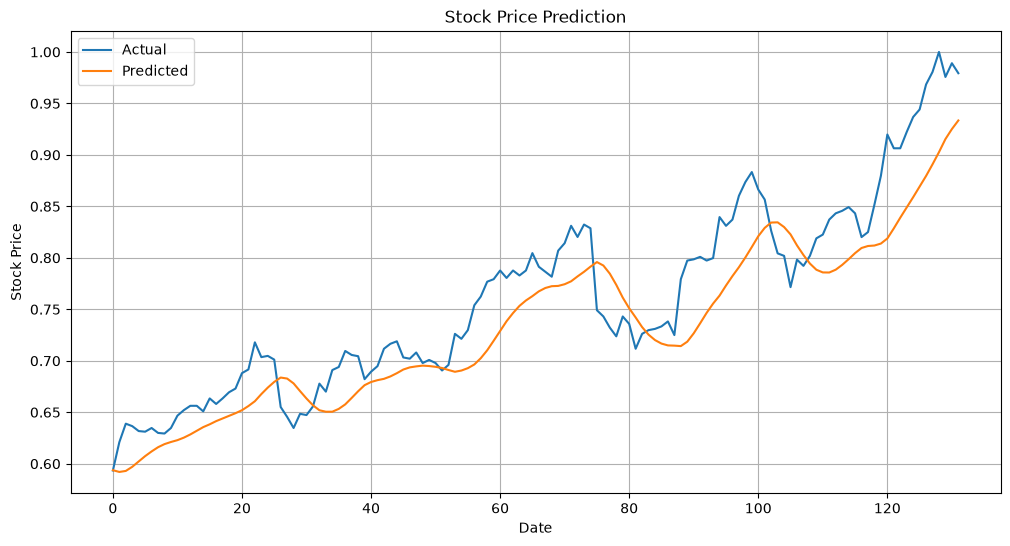

In [225]:
#2
plt.figure(figsize=(12, 6))
plt.xlabel("Date")
plt.ylabel("Stock Price")
plt.title("Stock Price Prediction")
plt.plot(testY, label='Actual')
plt.plot(testPredict, label='Predicted')
plt.grid(True)
plt.legend()
plt.show()

For this study, we will focus on the closing price, as it represents the final market sentiment for each trading day.